# Detecting change points with PELT

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. It reads the public observations and the original NumPy-seeded random innovations and bootstrap signs from local input files. Julia computes the regressions, recursive statistics, calibrations, bootstrap tests, and segmentations from those inputs and checks the stated numerical results. Figures use the requested dark theme, and outputs are saved under `outputs/julia`.

The chosen segmentation balances how well each segment fits against a cost for adding more change points:

$$
(\widehat m,\widehat\tau_1,\ldots,\widehat\tau_{\widehat m})
=\arg\min_{m,\,0=\tau_0<\cdots<\tau_{m+1}=T}
\left\{
\sum_{j=1}^{m+1}C\!\left(y_{\tau_{j-1}+1:\tau_j}\right)
+m\lambda
\right\},
\qquad
\lambda=\kappa\log T.
$$

Here, $T$ is series length; $m$ is the number of change points; $\tau_j$ is boundary $j.$ $y_{a:b}$ is the segment from $a$ through $b$; $C$ is its lack-of-fit cost; $\lambda$ is the cost per change point. $\kappa$ is the penalty multiplier; $\log$ is the natural logarithm; $\arg\min$ selects the segmentation with the smallest total.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("12_structural_breaks");
using CSV, Printf, TOML
using RiskLabAI.Features: compute_beta,get_bsadf_sequence,get_bubble_episodes,get_expanding_window_adf,get_gsadf_statistic,get_sadf_sequence,pelt_change_points,prepare_data,psy_minimum_window,simulate_psy_critical_values,volatility_robust_sadf
data_path = dataset_path("fred_nasdaq")
@assert isfile(data_path)
raw = CSV.read(data_path,DataFrame;missingstring=["","."])
raw.observation_date = Date.(raw.observation_date)
daily_price = sort(dropmissing(raw,:NASDAQCOM),:observation_date)
monthly_price = combine(groupby(transform(daily_price,:observation_date=>(dates->lastdayofmonth.(dates))=>:month),:month;sort=true),:NASDAQCOM=>last=>:price)
monthly_time = DateTime.(monthly_price.month)
log_price = log.(monthly_price.price)
monthly_return = diff(log_price)
return_time = monthly_time[2:end]
date_ticks = DateTime.(Date(1995):Year(5):Date(2025))
year_ticks = (Dates.value.(date_ticks),Dates.format.(date_ticks,dateformat"yyyy"))
replay_directory = joinpath("..","data","chapter12_random_inputs")
replay_manifest = TOML.parsefile(joinpath(replay_directory,"inputs.toml"))

function replay_matrix(name)
    filename = name*".csv"
    path = joinpath(replay_directory,filename)
    record = replay_manifest["files"][filename]
    values = Matrix(CSV.read(path,DataFrame))
    @assert size(values) == (record[],record["columns"])
    return values
end

function save_sequence(name,sequence;times=monthly_time)
    save_data(DataFrame(position=sequence.index,time=times[sequence.index],statistic=sequence.values),paths,name)
    return nothing
end


save_sequence (generic function with 1 method)

## Detecting changes in public moments

Row,Penalty multiplier,Penalty,Change points,Boundary dates
,Float64,Float64,Int64,String
1,1.5,8.92205,7,"1998-08-31, 2003-01-31, 2007-11-30, 2009-03-31, 2012-06-30, 2016-11-30, 2018-01-31"
2,2.0,11.8961,6,"1998-08-31, 2003-01-31, 2007-11-30, 2009-03-31, 2016-11-30, 2018-01-31"
3,2.5,14.8701,5,"1998-08-31, 2003-01-31, 2007-11-30, 2012-06-30, 2018-10-31"
4,3.0,17.8441,2,"1998-08-31, 2003-01-31"
5,4.0,23.7921,2,"1998-08-31, 2003-01-31"
6,6.0,35.6882,2,"1998-08-31, 2003-01-31"
7,8.0,47.5843,1,2003-01-31
8,10.0,59.4803,0,None


Row,Segment,First month,Last month,Months,"Annualized mean, percent","Annualized volatility, percent"
,Int64,String,String,Int64,Float64,Float64
1,1,1994-02-28,1998-07-31,54,18.8838,15.4962
2,2,1998-08-31,2002-12-31,53,-7.65062,40.2778
3,3,2003-01-31,2025-12-31,276,12.4202,17.5267


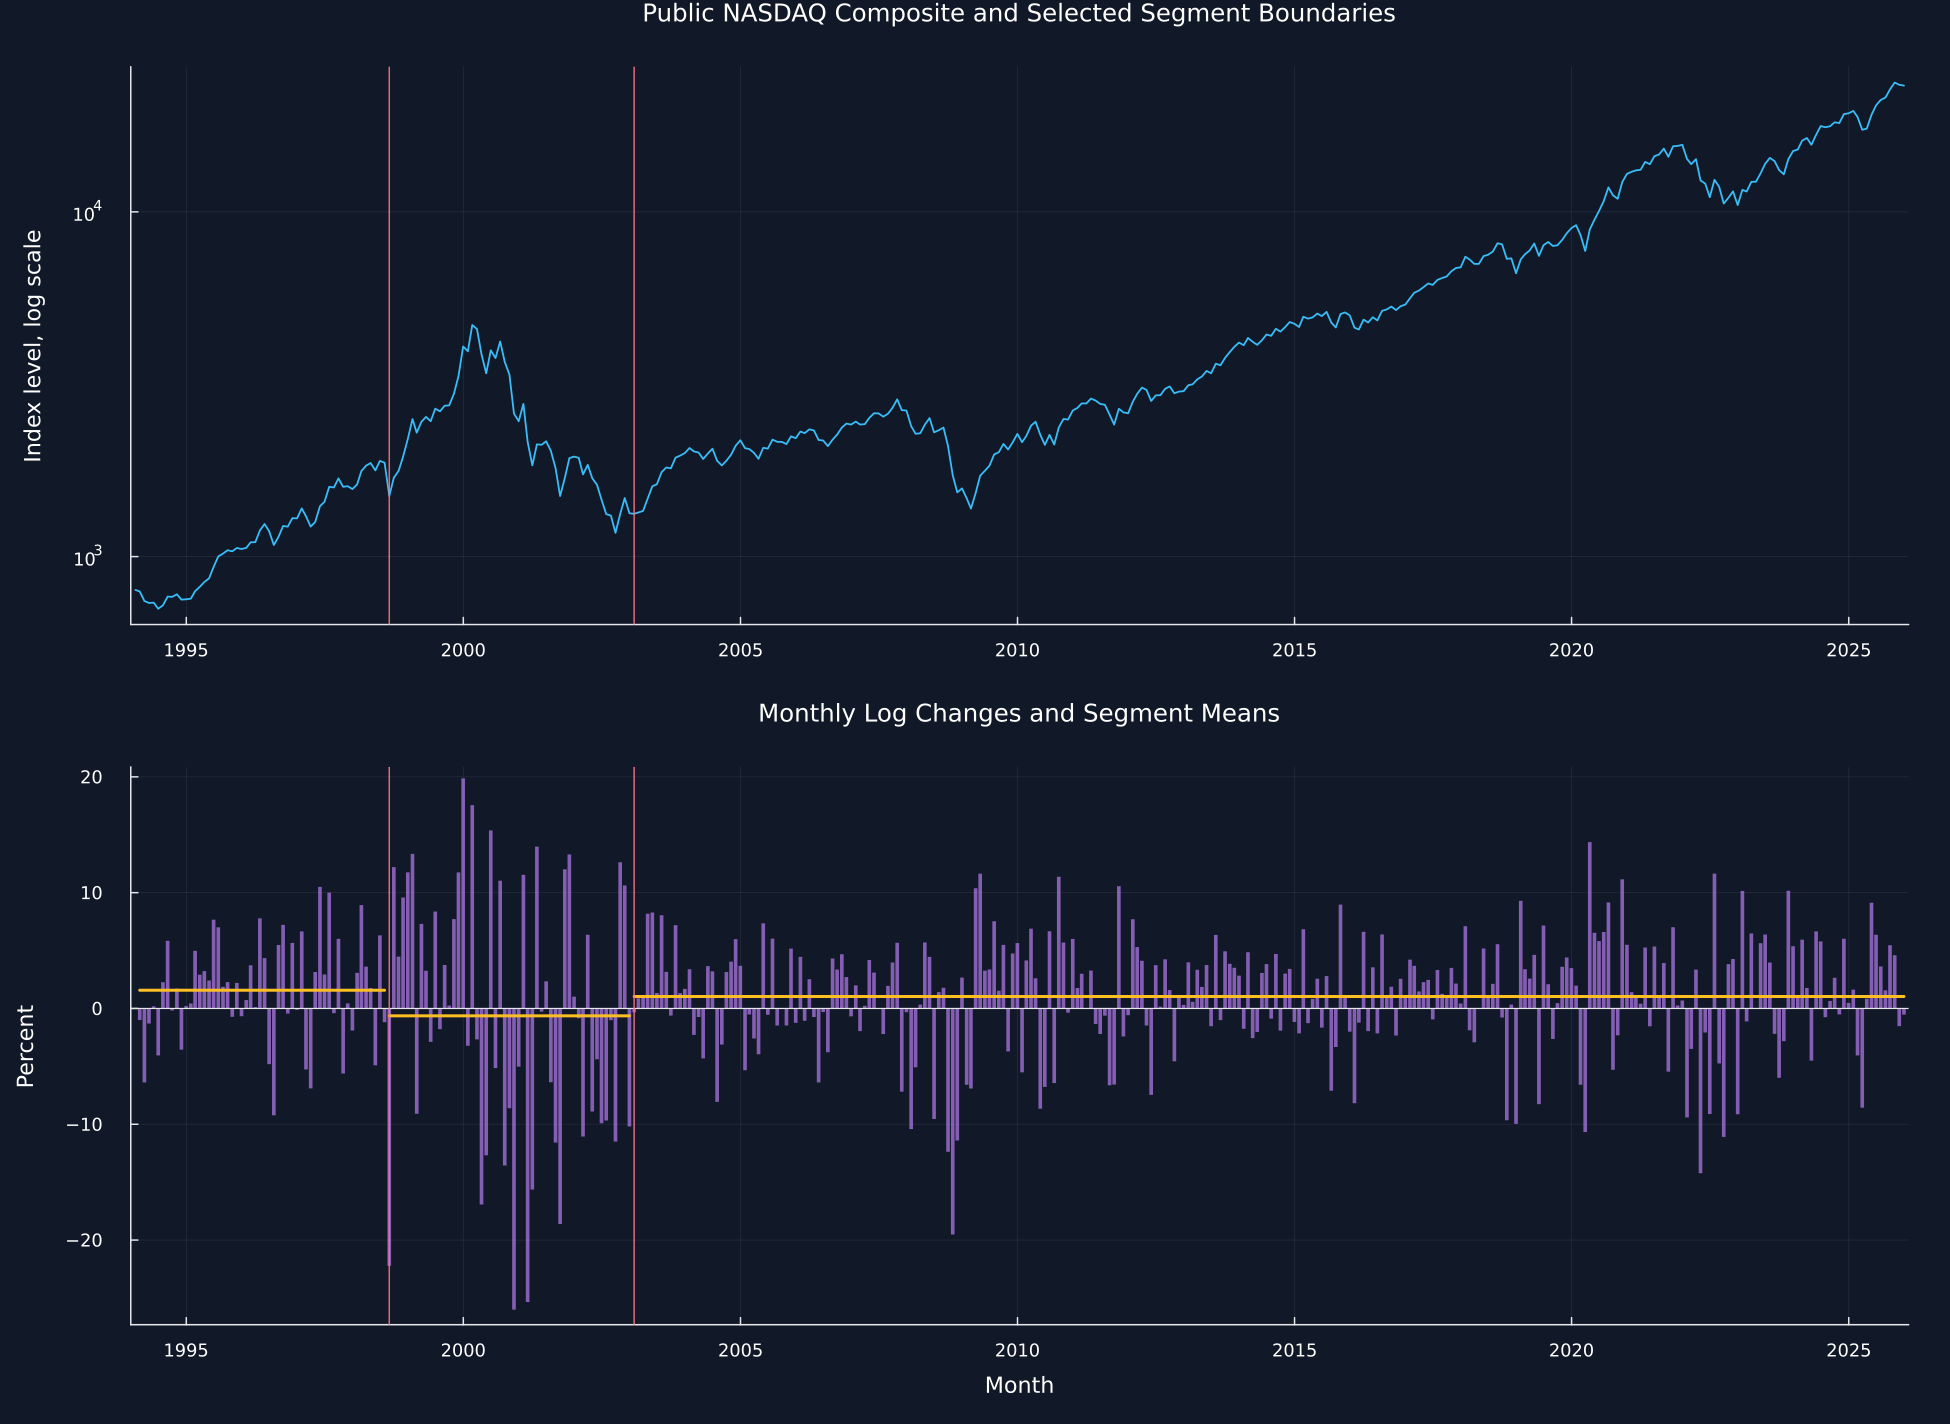

In [2]:
public_penalties = [1.5,2.,2.5,3.,4.,6.,8.,10.]
public_penalty_rows = NamedTuple[]
public_boundaries = Dict{Float64,Vector{Int}}()
public_boundary_rows = NamedTuple[]
for multiplier in public_penalties
    boundaries = pelt_change_points(monthly_return;model="normal",penalty_multiplier=multiplier,min_size=12,jump=1)
    public_boundaries[multiplier] = boundaries
    dates = string.(Date.(return_time[boundaries.+1]))
    push!(public_penalty_rows,(multiplier=multiplier,penalty=multiplier*log(length(monthly_return)),count=length(boundaries),dates=isempty(dates) ? "None" : join(dates,", ")))
    for boundary in boundaries
        push!(public_boundary_rows,(multiplier=multiplier,boundary=boundary,date=Date(return_time[boundary+1])))
    end
end
pelt_public_penalties = DataFrame(public_penalty_rows)
rename!(pelt_public_penalties,["Penalty multiplier","Penalty","Change points","Boundary dates"])
save_table(pelt_public_penalties,paths,"pelt_public_penalties";caption="Sensitivity of public change points to the penalty multiplier. Every month is an admissible boundary.",label="tab:chapter11-pelt-public-penalties")
chosen_multiplier = 3.
chosen_boundaries = public_boundaries[chosen_multiplier]
segment_edges = [0;chosen_boundaries;length(monthly_return)]
public_segment_rows = NamedTuple[]
for (number,(left,right)) in enumerate(zip(segment_edges[1:end-1],segment_edges[2:end]))
    values = monthly_return[left+1:right]
    push!(public_segment_rows,(segment=number,first=string(Date(return_time[left+1])),last=string(Date(return_time[right])),months=length(values),average=1200mean(values),volatility=100sqrt(12)*std(values)))
end
pelt_public_segments = DataFrame(public_segment_rows)
rename!(pelt_public_segments,["Segment","First month","Last month","Months","Annualized mean, percent","Annualized volatility, percent"])
save_table(pelt_public_segments,paths,"pelt_public_segments";caption="Public NASDAQ log-change segments at penalty multiplier 3.",label="tab:chapter11-pelt-public-segments")
boundary_dates = return_time[chosen_boundaries.+1]
p1 = plot(monthly_time,monthly_price.price;yscale=:log10,color=palette.cyan,linewidth=1.2,label=false,title="Public NASDAQ Composite and Selected Segment Boundaries",ylabel="Index level, log scale",xticks=year_ticks)
p2 = bar(return_time,100monthly_return;bar_width=Dates.value(Millisecond(Day(24))),color="#C084FC",alpha=.65,linealpha=0,label=false,title="Monthly Log Changes and Segment Means",xlabel="Month",ylabel="Percent",xticks=year_ticks)
for (left,right,row) in zip(segment_edges[1:end-1],segment_edges[2:end],public_segment_rows)
    plot!(p2,return_time[[left+1,right]],fill(row.average/12,2);color=palette.amber,linewidth=2,label=false)
end
hline!(p2,[0];color=palette.text,linewidth=.8,label=false)
for panel in [p1,p2]
    vline!(panel,Dates.value.(boundary_dates);color=palette.rose,linewidth=1,alpha=.9,label=false)
end
plot!(p2;ylims=(105minimum(monthly_return),105maximum(monthly_return)))
save_figure(plot(p1,p2;layout=(2,1),size=(1300,950),left_margin=6Plots.mm,xlims=(Dates.value(first(monthly_time)-Day(31)),Dates.value(last(monthly_time)+Day(31)))),paths,"pelt_public_segments")
save_data(DataFrame(public_boundary_rows),paths,"pelt_public_boundaries");


## How PELT pruning follows the recursion

The recursion builds an optimal segmentation from earlier optimal pieces, and the inequality removes a candidate that cannot become best later:

$$
F(s)=\min_{0\leq t<s}\left\{F(t)+C(y_{t+1:s})+\lambda\right\},
\qquad
F(t)+C(y_{t+1:s})+K\geq F(s)
\ \Longrightarrow\ 
t\text{ may be removed from later searches}.
$$

Here, $F(s)$ is the smallest penalized cost through observation $s$; $t$ is a candidate last boundary before $s.$ $C(y_{t+1:s})$ is the cost of the last segment; $\lambda$ is the cost per boundary; $K$ is a constant allowed by the segment cost. $\min$ selects the smallest candidate cost; $\Longrightarrow$ states the pruning implication.

## A Known-Truth Segmentation

The controlled series has one mean change, one pure variance change, and one combined mean and variance change:

$$
X_t\sim\mathcal N(\mu_j,\sigma_j^2),
\qquad
(\tau_1,\tau_2,\tau_3)=(60,140,195),
\qquad
(\mu_j)=(0,1.2,1.2,-0.8),
\qquad
(\sigma_j)=(1,1,2.5,1).
$$

Here, $X_t$ is observation $t$; $\mathcal N(\mu_j,\sigma_j^2)$ is a normal distribution in segment $j.$ $\tau_1,\tau_2,\tau_3$ are the known boundaries; $\mu_j$ is the segment mean; $\sigma_j$ is the segment standard deviation. $t$ runs from 0 through 239; the four segment lengths are $60,80,55,$ and $45.$

Row,Item,Value
,String,String
1,Observations,240
2,True boundaries,"60, 140, 195"
3,Segment lengths,"60, 80, 55, 45"
4,Segment means,"0, 1.2, 1.2, -0.8"
5,Segment standard deviations,"1, 1, 2.5, 1"
6,Repetitions,24
7,Match tolerance,10
8,Minimum segment,15
9,Candidate spacing,1


Row,Segment cost,Penalty multiplier,Boundary recall,Pure-variance recall,False boundaries per path,Exact three-boundary paths,Mean location error
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Mean and variance,2.0,0.972222,0.958333,0.25,0.791667,1.38571
2,Mean and variance,3.0,0.972222,0.958333,0.0833333,0.916667,1.37143
3,Mean and variance,6.0,0.916667,0.916667,0.0416667,0.75,1.45455
4,Mean only,3.0,0.666667,0.291667,0.916667,0.0416667,2.1875


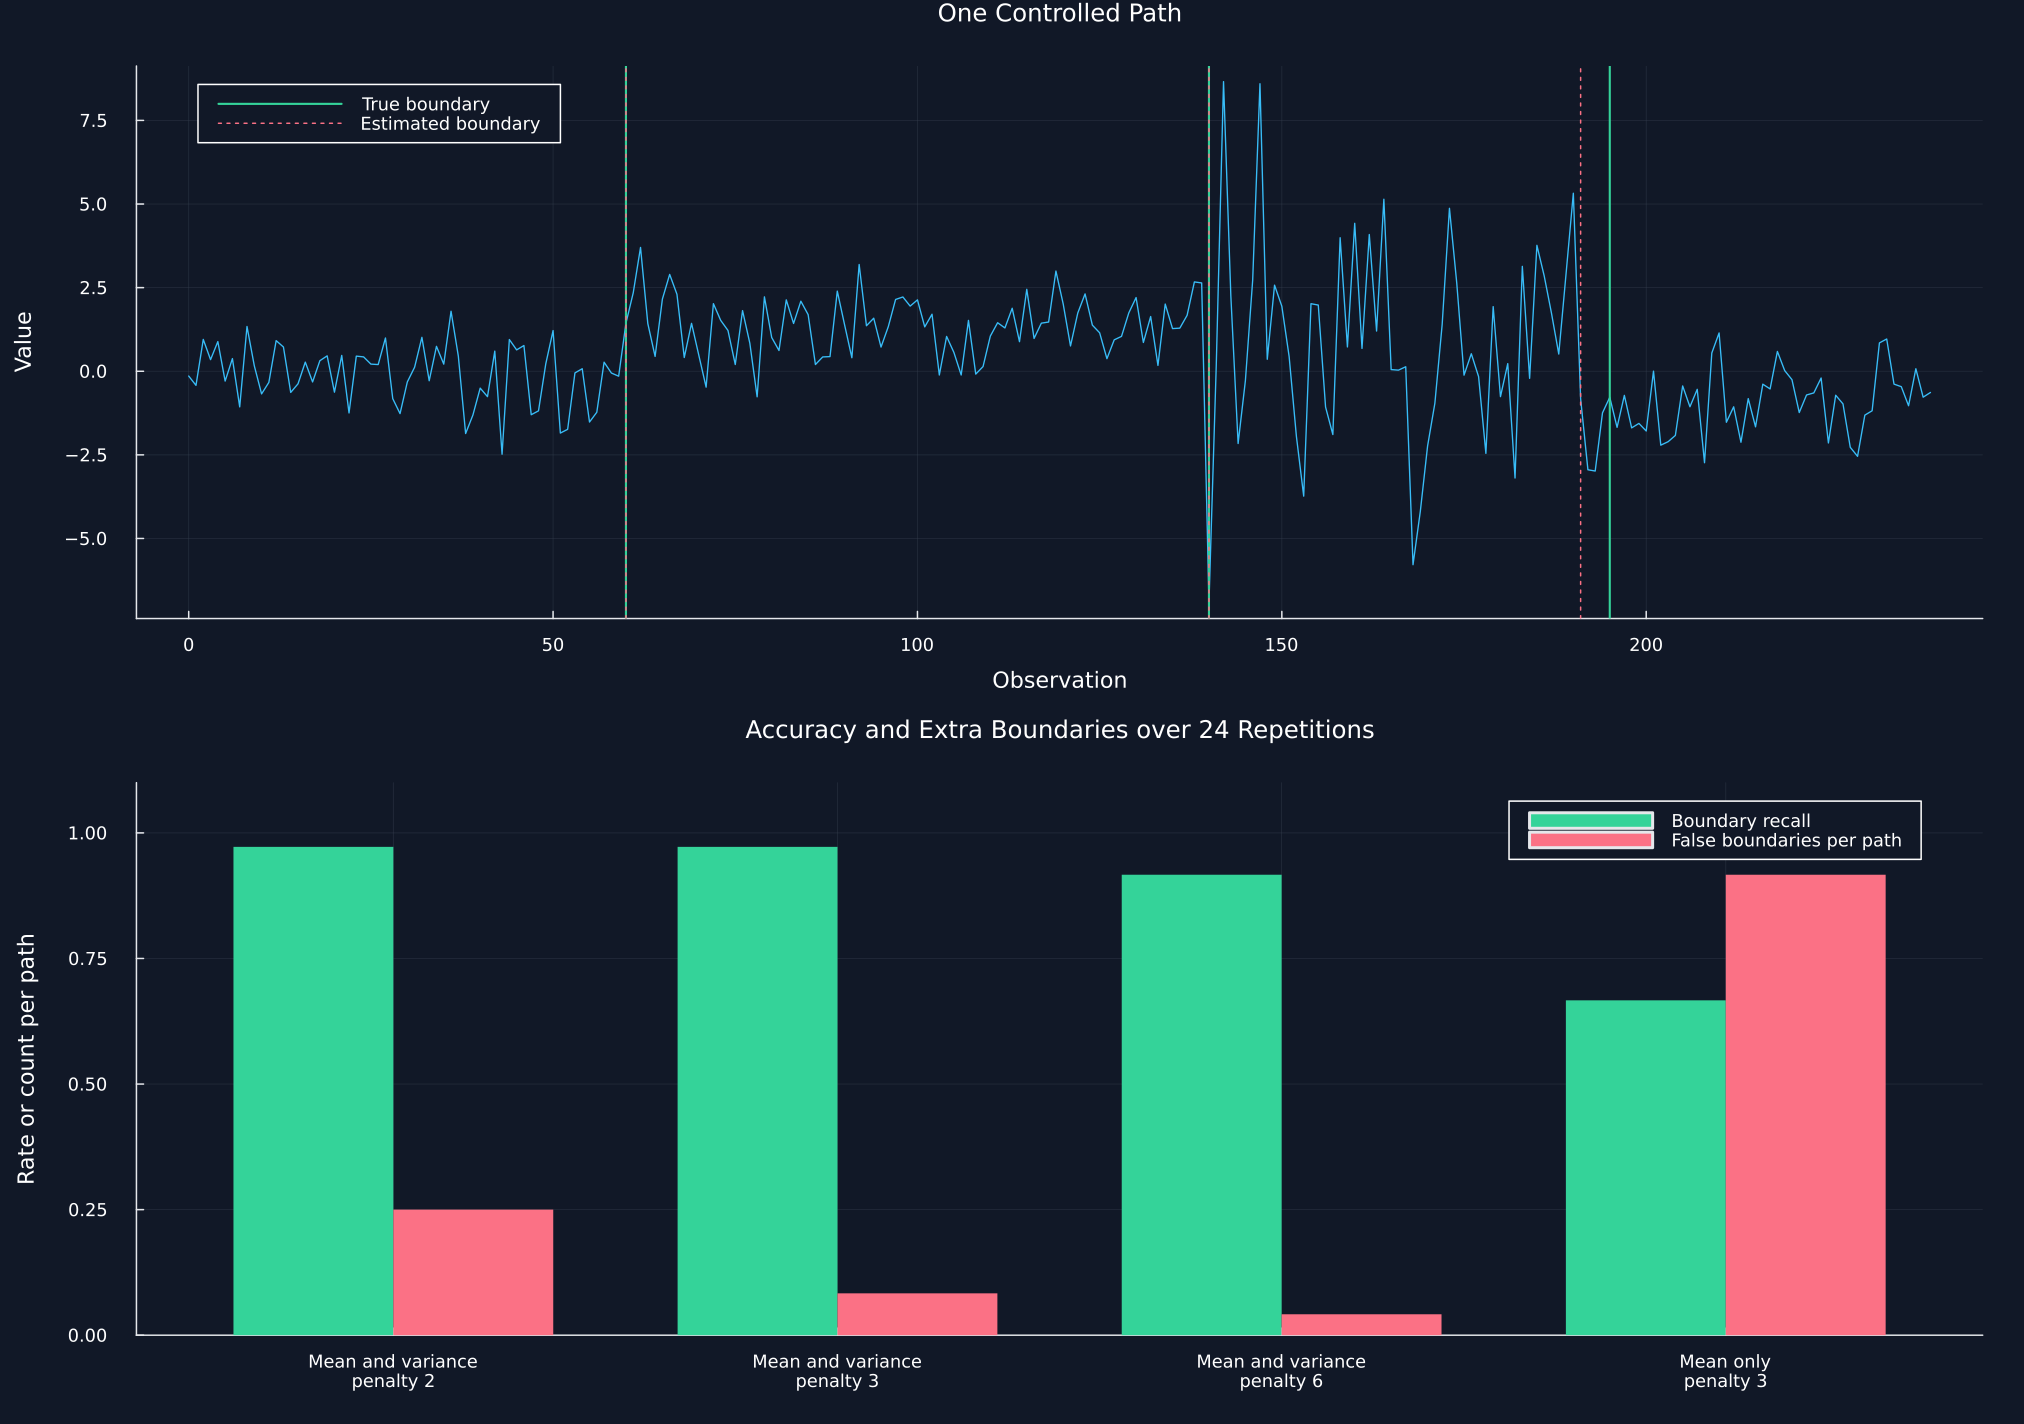

In [3]:
true_boundaries = [60,140,195]
segment_lengths = [60,80,55,45]
segment_means = [0.,1.2,1.2,-.8]
segment_standard_deviations = [1.,1.,2.5,1.]
controlled_repetitions = 24
matching_tolerance = 10
controlled_configurations = [("Mean and variance",2.),("Mean and variance",3.),("Mean and variance",6.),("Mean only",3.)]
pelt_controlled_design = DataFrame("Item"=>["Observations","True boundaries","Segment lengths","Segment means","Segment standard deviations","Repetitions","Match tolerance","Minimum segment","Candidate spacing"],"Value"=>["240","60, 140, 195","60, 80, 55, 45","0, 1.2, 1.2, -0.8","1, 1, 2.5, 1",string(controlled_repetitions),string(matching_tolerance),"15","1"])
save_table(pelt_controlled_design,paths,"pelt_controlled_design";caption="Known-truth change-point experiment.",label="tab:chapter11-pelt-controlled-design")
pelt_normals = replay_matrix("pelt_normals")
segment_scales = vcat([fill(value,count) for (value,count) in zip(segment_standard_deviations,segment_lengths)]...)
segment_centers = vcat([fill(value,count) for (value,count) in zip(segment_means,segment_lengths)]...)
controlled_series = permutedims(pelt_normals).*segment_scales.+segment_centers
function match_boundaries(predicted)
    remaining = copy(predicted)
    errors,matched = Int[],Int[]
    for truth in true_boundaries
        candidates = findall(value->abs(value-truth)<=matching_tolerance,remaining)
        if !isempty(candidates)
            position = candidates[argmin(abs.(remaining[candidates].-truth))]
            chosen = popat!(remaining,position)
            push!(errors,abs(chosen-truth))
            push!(matched,truth)
        end
    end
    return matched,remaining,errors
end
controlled_rows = NamedTuple[]
controlled_run_rows = NamedTuple[]
controlled_boundary_rows = NamedTuple[]
for (configuration,(cost_name,multiplier)) in enumerate(controlled_configurations)
    model = cost_name=="Mean and variance" ? "normal" : "l2"
    matched_total,variance_matches,false_total,exact_total = 0,0,0,0
    all_errors = Int[]
    for repetition in 0:controlled_repetitions-1
        values = controlled_series[:,repetition+1]
        predicted = pelt_change_points(values;model=model,penalty_multiplier=multiplier,min_size=15,jump=1)
        matched,remaining,errors = match_boundaries(predicted)
        matched_total += length(matched)
        variance_matches += 140 in matched
        false_total += length(remaining)
        exact_total += length(matched)==length(true_boundaries)&&isempty(remaining)
        append!(all_errors,errors)
        push!(controlled_run_rows,(configuration=configuration,repetition=repetition,model=model,multiplier=multiplier,boundaries=length(predicted),matched=length(matched),variance_matched=140 in matched,false_boundaries=length(remaining),exact=length(matched)==length(true_boundaries)&&isempty(remaining),total_error=sum(errors)))
        for boundary in predicted
            push!(controlled_boundary_rows,(configuration=configuration,repetition=repetition,boundary=boundary))
        end
    end
    push!(controlled_rows,(cost=cost_name,multiplier=multiplier,recall=matched_total/(controlled_repetitions*length(true_boundaries)),variance_recall=variance_matches/controlled_repetitions,false_boundaries=false_total/controlled_repetitions,exact=exact_total/controlled_repetitions,error=mean(all_errors)))
end
pelt_controlled_accuracy = DataFrame(controlled_rows)
rename!(pelt_controlled_accuracy,["Segment cost","Penalty multiplier","Boundary recall","Pure-variance recall","False boundaries per path","Exact three-boundary paths","Mean location error"])
save_table(pelt_controlled_accuracy,paths,"pelt_controlled_accuracy";caption="Known-truth change-point accuracy across segment costs and penalties.",label="tab:chapter11-pelt-controlled-accuracy")
example_values = controlled_series[:,1]
example_boundaries = pelt_change_points(example_values;model="normal",penalty_multiplier=3.,min_size=15,jump=1)
p1 = plot(0:length(example_values)-1,example_values;color=palette.cyan,linewidth=.9,label=false,title="One Controlled Path",xlabel="Observation",ylabel="Value",legend=:topleft)
vline!(p1,true_boundaries;color=palette.green,linewidth=1.4,label="True boundary")
vline!(p1,example_boundaries;color=palette.rose,linewidth=1,linestyle=:dot,label="Estimated boundary")
labels = [row.cost*"\npenalty "*@sprintf("%g",row.multiplier) for row in controlled_rows]
maximum_rate = maximum(Matrix(pelt_controlled_accuracy[:,["Boundary recall","False boundaries per path"]]))
p2 = bar((1:4).- .18,pelt_controlled_accuracy[!,"Boundary recall"];bar_width=.36,color=palette.green,linealpha=0,label="Boundary recall",xticks=(1:4,labels),ylims=(0,max(1.1,1.1maximum_rate)),title="Accuracy and Extra Boundaries over 24 Repetitions",ylabel="Rate or count per path",legend=:topright)
bar!(p2,(1:4).+ .18,pelt_controlled_accuracy[!,"False boundaries per path"];bar_width=.36,color=palette.rose,linealpha=0,label="False boundaries per path")
save_figure(plot(p1,p2;layout=(2,1),size=(1350,950),left_margin=6Plots.mm),paths,"pelt_known_truth")
save_data(DataFrame(position=repeat(0:239;outer=24),repetition=repeat(0:23;inner=240),value=vec(controlled_series)),paths,"pelt_controlled_paths");
save_data(DataFrame(controlled_run_rows),paths,"pelt_controlled_runs");
save_data(DataFrame(controlled_boundary_rows),paths,"pelt_controlled_boundaries");


## Tests

In [4]:
@assert length(monthly_return)==383
@assert issorted(public_penalties)
@assert size(pelt_public_penalties)==(8,4)
@assert issorted(pelt_public_penalties[!,"Change points"];rev=true)
@assert public_boundaries[3.]==[54,107]
@assert chosen_boundaries==[54,107]
@assert string.(Date.(boundary_dates))==["1998-08-31","2003-01-31"]
@assert nrow(pelt_public_segments)==3
@assert sum(pelt_public_segments.Months)==length(monthly_return)
@assert minimum(pelt_public_segments.Months)>=12
@assert all(pelt_public_segments[!,"Annualized volatility, percent"].>0)
@assert true_boundaries==[60,140,195]
@assert sum(segment_lengths)==240
@assert controlled_repetitions==24
@assert size(pelt_controlled_accuracy)==(4,7)
@assert all(0 .<=pelt_controlled_accuracy[!,"Boundary recall"].<=1)
@assert all(0 .<=pelt_controlled_accuracy[!,"Pure-variance recall"].<=1)
@assert all(pelt_controlled_accuracy[!,"False boundaries per path"].>=0)
@assert all(0 .<=pelt_controlled_accuracy[!,"Exact three-boundary paths"].<=1)
@assert all(pelt_controlled_accuracy[!,"Mean location error"].<=matching_tolerance)
@assert pelt_controlled_accuracy[2,"Boundary recall"]>=.90
@assert pelt_controlled_accuracy[2,"Pure-variance recall"]>=.90
@assert pelt_controlled_accuracy[2,"False boundaries per path"]<=.20
@assert pelt_controlled_accuracy[2,"Exact three-boundary paths"]>=.80
@assert pelt_controlled_accuracy[2,"Pure-variance recall"]>pelt_controlled_accuracy[4,"Pure-variance recall"]
@assert all(abs(value-truth)<=matching_tolerance for (value,truth) in zip(example_boundaries,true_boundaries))
@assert isfile(joinpath(paths.figures,"pelt_public_segments.pdf"))
@assert isfile(joinpath(paths.figures,"pelt_known_truth.pdf"))
@assert isfile(joinpath(paths.tables,"pelt_public_penalties.tex"))
@assert isfile(joinpath(paths.tables,"pelt_public_segments.tex"))
@assert isfile(joinpath(paths.tables,"pelt_controlled_design.tex"))
@assert isfile(joinpath(paths.tables,"pelt_controlled_accuracy.tex"))
